# Dependencias

In [259]:
## Instalando Dependencias

%pip install pandas
%pip install matplotlib
%pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Imports

In [260]:
## Fazendo os imports

# utils
from pathlib import Path
from urllib.request import urlretrieve 

# data science
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.model_selection import GridSearchCV

from matplotlib import pyplot as plt

# Baixando o dataset caso não exista

In [261]:
## Baixando o dataset

url = "https://raw.githubusercontent.com/vqrca/ml-datasets/refs/heads/main/Heart_Disease_Prediction.csv"
filename = "Heart_Disease_Prediction.csv"

def download_dataset(url:str, filename:str) -> None:
    """Download the dataset from the given URL and save it to the specified filename."""
    if Path(filename).exists():
        print(f"Dataset already exists as {filename}. Skipping download.")
        return
    urlretrieve(url, filename)
    print(f"Dataset downloaded and saved as {filename}")

download_dataset(url, filename)

Dataset already exists as Heart_Disease_Prediction.csv. Skipping download.


# Função de plotar o gráfico

In [262]:
## Utils

def plt_tree_visualization(width, height, fontsize, model, feature_names, max_depth=None):
    """Visualize the decision tree model."""
    plt.figure(figsize=(width, height))
    plot_tree(model, 
              feature_names=feature_names, 
              filled=True,
              rounded=True,
              fontsize=fontsize,
              proportion=True,
              precision=2,
              max_depth=max_depth
            )
    plt.tight_layout()
    plt.show()

# Entendendo o Dataset

In [263]:
## Lendo o dataset

df = pd.read_csv(filename)

pd.set_option('display.max_columns', None)  # Display all columns
df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [264]:
## Entendendo o shape do dataset

# (270,14)
# 270 linhas e 14 colunas
df.shape

(270, 14)

In [265]:
## Entendendo o tipo de cada coluna do dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    str    
dtypes: float64(1), int64(12), str(1)
memo

# Tratando dados categoricos

In [266]:
## Tratando os valores categoricos do dataset usando o método get_dummies do pandas

# os valores categoricos dessas colunas sao convertidos pelo método get_dummies do pandas em valores numericos
# onde cada valor categorico é representado por uma coluna binaria (0 ou 1). 

df_encoded = pd.get_dummies(df, columns=['Chest pain type', 'Thallium'], dtype=int)
df_encoded.head()

,Age,Sex,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Heart Disease,Chest pain type_1,Chest pain type_2,Chest pain type_3,Chest pain type_4,Thallium_3,Thallium_6,Thallium_7
0,70,1,130,322,0,2,109,0,2.4,2,3,Presence,0,0,0,1,1,0,0
1,67,0,115,564,0,2,160,0,1.6,2,0,Absence,0,0,1,0,0,0,1
2,57,1,124,261,0,0,141,0,0.3,1,0,Presence,0,1,0,0,0,0,1
3,64,1,128,263,0,0,105,1,0.2,2,1,Absence,0,0,0,1,0,0,1
4,74,0,120,269,0,2,121,1,0.2,1,1,Absence,0,1,0,0,1,0,0


# Preparando Treino e Teste

In [267]:
## Separando as features (X) e o target (y)

# X - features
# todos os valores do dataset, exceto a coluna 'Heart Disease', que é o target
X_Features = df_encoded.drop('Heart Disease', axis=1)

# y - target
# apenas a coluna 'Heart Disease', que é o target
y_target = df_encoded['Heart Disease']

In [268]:
## Como o as features (X) ficaram
X_Features

,Age,Sex,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Chest pain type_1,Chest pain type_2,Chest pain type_3,Chest pain type_4,Thallium_3,Thallium_6,Thallium_7
0,70,1,130,322,0,2,109,0,2.4,2,3,0,0,0,1,1,0,0
1,67,0,115,564,0,2,160,0,1.6,2,0,0,0,1,0,0,0,1
2,57,1,124,261,0,0,141,0,0.3,1,0,0,1,0,0,0,0,1
3,64,1,128,263,0,0,105,1,0.2,2,1,0,0,0,1,0,0,1
4,74,0,120,269,0,2,121,1,0.2,1,1,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,172,199,1,0,162,0,0.5,1,0,0,0,1,0,0,0,1
266,44,1,120,263,0,0,173,0,0.0,1,0,0,1,0,0,0,0,1
267,56,0,140,294,0,2,153,0,1.3,2,0,0,1,0,0,1,0,0
268,57,1,140,192,0,0,148,0,0.4,2,0,0,0,0,1,0,1,0


In [269]:
## Como o target (y) ficou
y_target

0      Presence
1       Absence
2      Presence
3       Absence
4       Absence
         ...   
265     Absence
266     Absence
267     Absence
268     Absence
269    Presence
Name: Heart Disease, Length: 270, dtype: str

In [270]:
## Separando os dados em treino e teste

# random_state 42 para reprodubilidade
X_Features_treino, X_Features_teste, y_target_treino, y_target_teste = train_test_split(X_Features, y_target, test_size=0.2, random_state=42, stratify=y_target)

In [271]:
# X treino
print("X treino:")
display(X_Features.shape)
display(X_Features_treino.shape)
print(f"% treino: {X_Features_treino.shape[0] / X_Features.shape[0] * 100:.2f}%")
print('------')

# y treino
print("y treino:")
display(y_target.shape)
display(y_target_treino.shape)
print(f"% treino: {y_target_treino.shape[0] / y_target.shape[0] * 100:.2f}%")
print('------')

# X teste
print("X teste:")
display(X_Features.shape)
display(X_Features_teste.shape)
print(f"% teste: {X_Features_teste.shape[0] / X_Features.shape[0] * 100:.2f}%")
print('------')

# y teste
print("y teste:")
display(y_target.shape)
display(y_target_teste.shape)
print(f"% teste: {y_target_teste.shape[0] / y_target.shape[0] * 100:.2f}%")
print('------')

X treino:


(270, 18)

(216, 18)

% treino: 80.00%
------
y treino:


(270,)

(216,)

% treino: 80.00%
------
X teste:


(270, 18)

(54, 18)

% teste: 20.00%
------
y teste:


(270,)

(54,)

% teste: 20.00%
------


# Treinamento Normal

In [272]:
## Treinando o modelo usando DecisionTreeClassifier do scikit-learn

# random_state 5389 para reprodubilidade
# inicializa o modelo passando os dados de treino (X e y)
# o fit método é usado para treinar o modelo com os dados de treino
model_tree = DecisionTreeClassifier(random_state=5389)
model_tree.fit(X_Features_treino, y_target_treino)

# o predict método é usado para fazer previsões com o modelo treinado, passando os dados de teste (X)
# aqui ele compara os dados de teste (X) com o modelo treinado e retorna as previsões (y)
predict = model_tree.predict(X_Features_teste)

In [273]:
predict

array(['Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Absence',
       'Absence', 'Presence', 'Presence', 'Presence', 'Absence',
       'Presence', 'Absence', 'Presence', 'Presence', 'Presence',
       'Absence', 'Presence', 'Absence', 'Presence', 'Absence',
       'Presence', 'Absence', 'Absence', 'Absence', 'Presence',
       'Presence', 'Absence', 'Absence', 'Presence', 'Absence', 'Absence',
       'Presence', 'Absence', 'Absence', 'Presence', 'Presence',
       'Absence', 'Absence', 'Absence', 'Presence', 'Absence', 'Presence',
       'Presence', 'Presence', 'Presence', 'Absence', 'Presence',
       'Presence', 'Absence', 'Presence', 'Presence', 'Absence',
       'Presence'], dtype=object)

In [274]:
## Calculando as probabilidades do modelo

# aqui usamos o método predict_proba do modelo treinado para obter as probabilidades de cada classe para os dados de teste (X)
proba = model_tree.predict_proba(X_Features_teste)

In [275]:
proba

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.]])

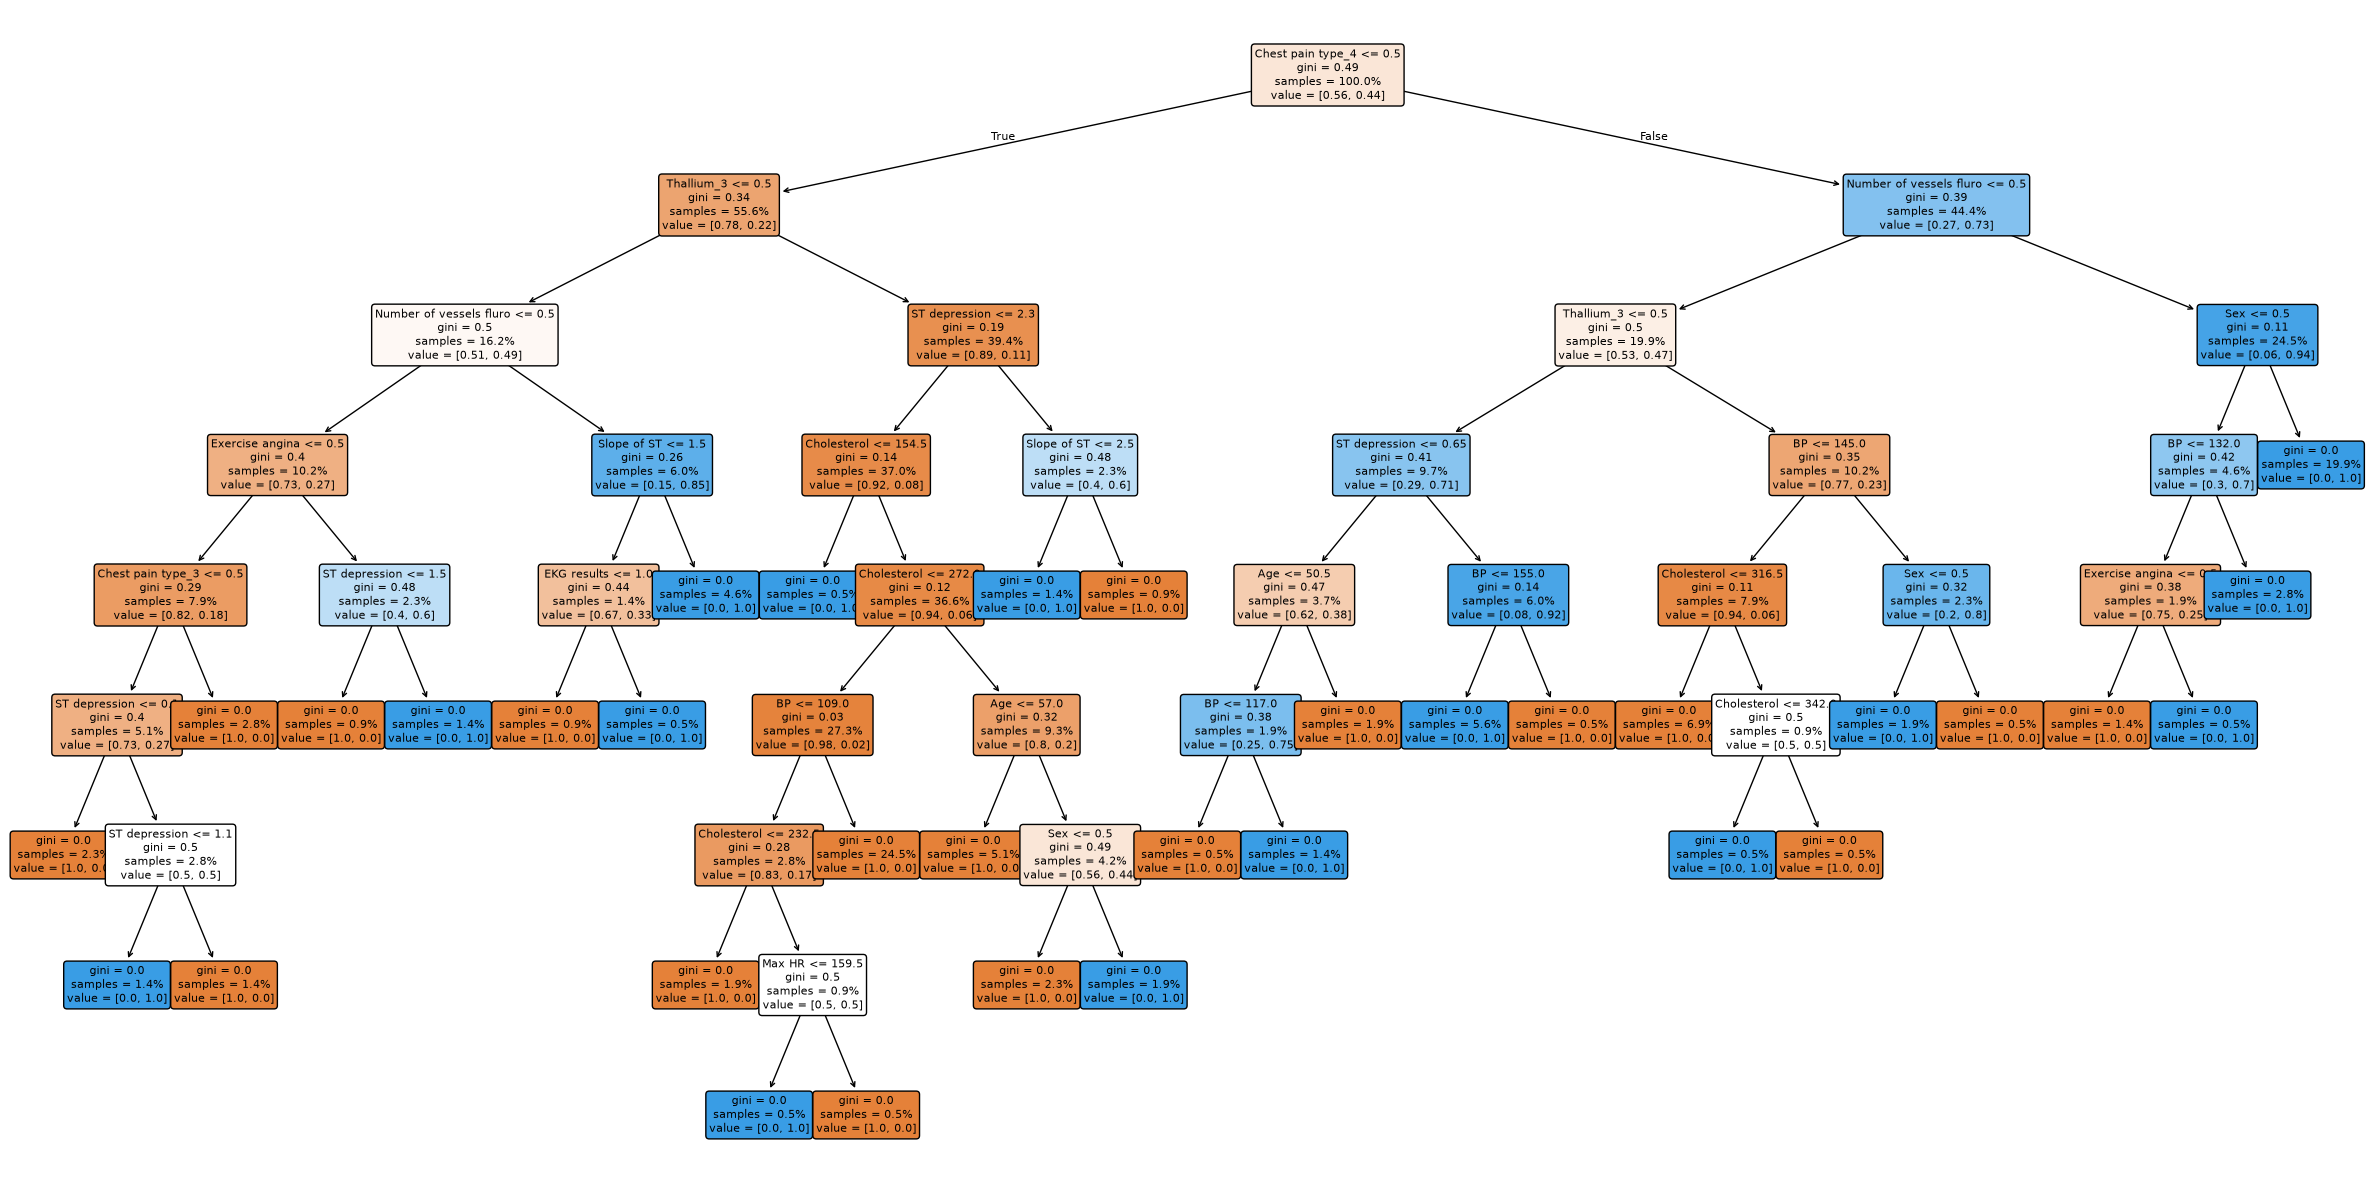

In [276]:
## Vendo o resultado do treinamento

plt_tree_visualization(width=24, 
                       height=12, 
                       fontsize=8, 
                       model=model_tree, 
                       feature_names=X_Features.columns
                       )

In [277]:
## Analisando a acurácia do modelo

y_target_accuracy = accuracy_score(y_target_teste, predict)
print(f"Acurácia do modelo: {y_target_accuracy:.2f}")

predict_treino = model_tree.predict(X_Features_treino)

y_target_accuracy_treino = accuracy_score(y_target_treino, predict_treino)
print(f"Acurácia do modelo no conjunto de treino: {y_target_accuracy_treino:.2f}")

# deu overfitting porque o modelo teve 100% de acurácia no conjunto de treino

Acurácia do modelo: 0.80
Acurácia do modelo no conjunto de treino: 1.00


In [278]:
## Classification Report

report = classification_report(y_target_teste, predict)
print("Relatório de Classificação:")
print(report)

Relatório de Classificação:
              precision    recall  f1-score   support

     Absence       0.85      0.77      0.81        30
    Presence       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54



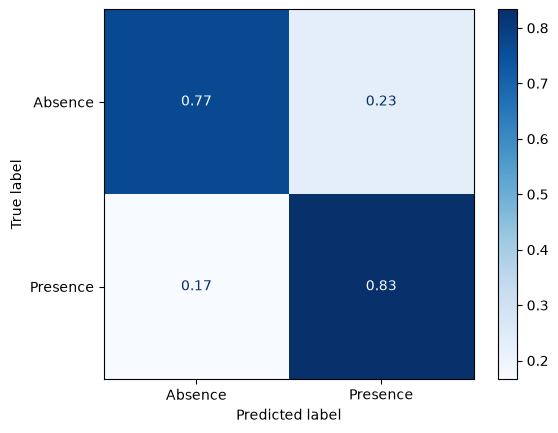

In [279]:
## Matriz de Confusão

ConfusionMatrixDisplay.from_estimator(model_tree, 
                                      X_Features_teste, 
                                      y_target_teste, 
                                      normalize='true', 
                                      cmap=plt.cm.Blues)

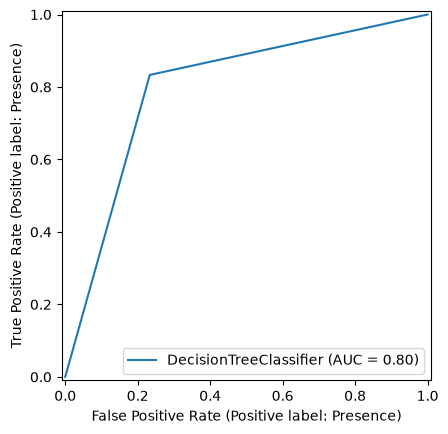

In [280]:
## Entendo a ROC Curve

RocCurveDisplay.from_estimator(model_tree,
                               X_Features_teste,
                               y_target_teste
                               )

# Treinamento com poda de arvore

- definindo a profundidade da arvore

In [281]:
## Tentando controllar o overfitting com max_depth

model_tree_depth = DecisionTreeClassifier(random_state=5389, max_depth=3)
model_tree_depth.fit(X_Features_treino, y_target_treino)

predict_depth = model_tree_depth.predict(X_Features_teste)
predict_depth_treino = model_tree_depth.predict(X_Features_treino)

In [282]:
accuracy_depth = accuracy_score(y_target_teste, predict_depth)
print(f"Acurácia do modelo com max_depth=3: {accuracy_depth:.2f}")

accuracy_depth_treino = accuracy_score(y_target_treino, predict_depth_treino)
print(f"Acurácia do modelo com max_depth=3 no conjunto de treino: {accuracy_depth_treino:.2f}")

Acurácia do modelo com max_depth=3: 0.83
Acurácia do modelo com max_depth=3 no conjunto de treino: 0.86


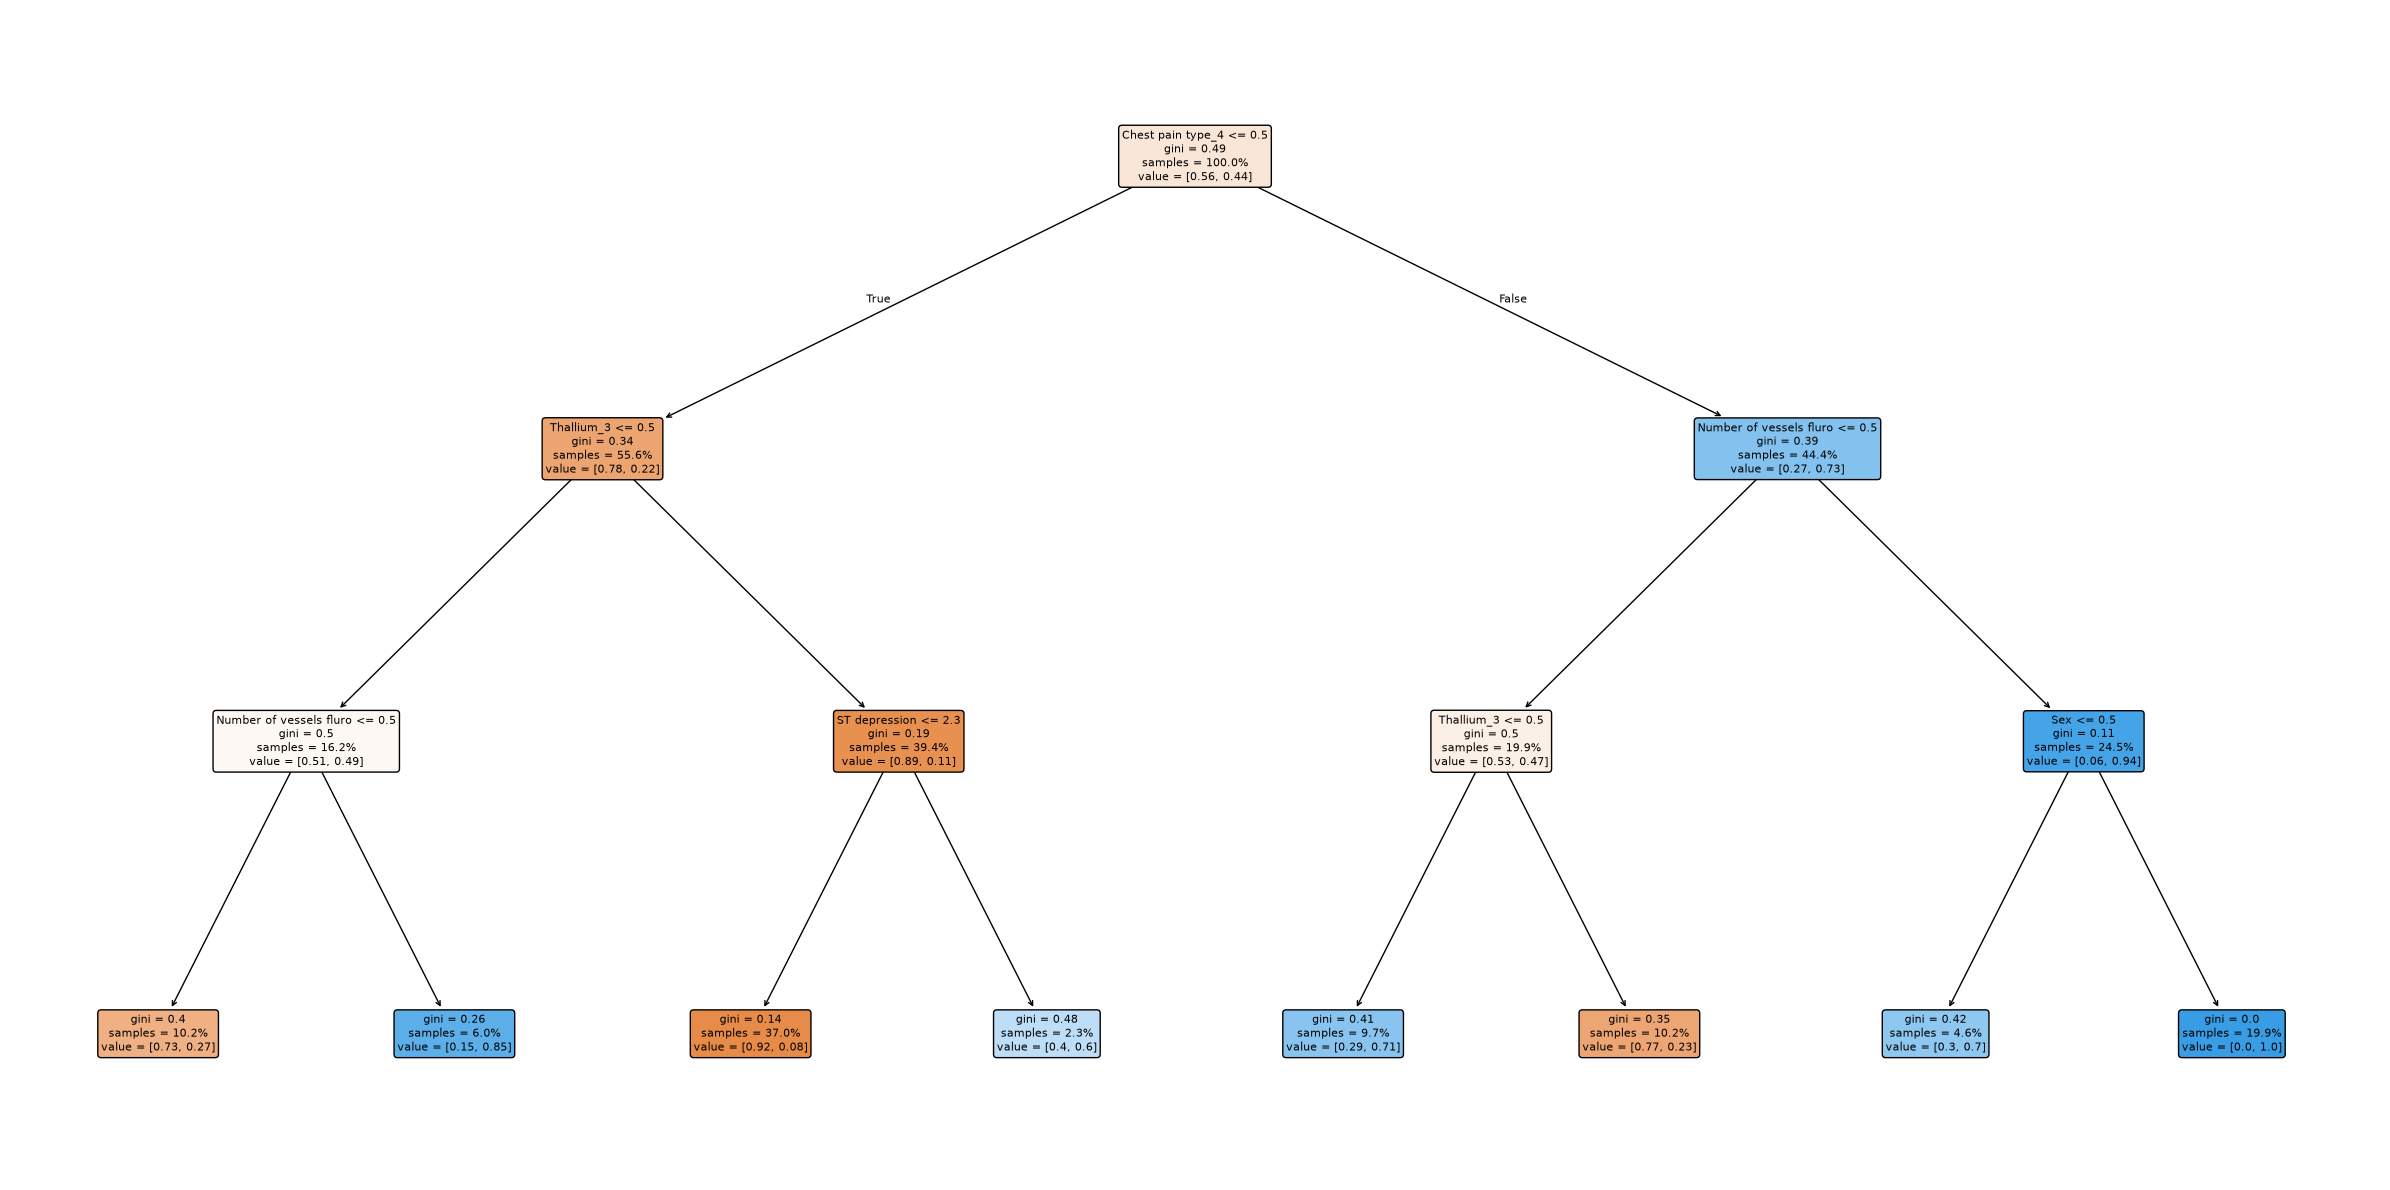

In [283]:
plt_tree_visualization(width=24, 
                       height=12, 
                       fontsize=8,
                       model=model_tree_depth,
                       feature_names=X_Features.columns,
                       max_depth=3
                       )

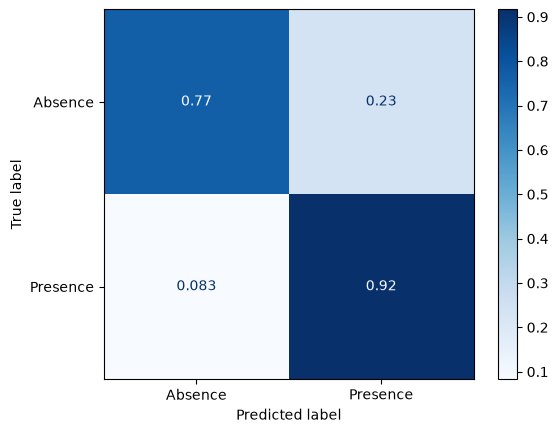

In [284]:
## Vendo a matriz de confusão do modelo com max_depth=3

ConfusionMatrixDisplay.from_estimator(model_tree_depth,
                                      X_Features_teste,
                                      y_target_teste,
                                      normalize='true',
                                      cmap=plt.cm.Blues)

In [285]:
## Usando validação cruzada (cross-validation) para avaliar o modelo

model_tree_cv = DecisionTreeClassifier(random_state=5389, max_depth=3)
scores = cross_val_score(model_tree_cv, X_Features_treino, y_target_treino, cv=5, scoring='accuracy')
display(scores)
print("O resultado da validação cruzada é %0.2f%% acurácia com desvio padrão de %0.2f%%" 
      % (scores.mean() * 100, scores.std() * 100))

## scores mostra os valores de acurácia para cada uma das 5 folds (partições) do conjunto de dados.

array([0.77272727, 0.74418605, 0.81395349, 0.76744186, 0.74418605])

O resultado da validação cruzada é 76.85% acurácia com desvio padrão de 2.56%


In [286]:
## Validação cruzada estratégica (Stratified K-Fold Cross-Validation)

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=5389)
scores = cross_val_score(model_tree_cv, X_Features_treino, y_target_treino, cv=validation, scoring='accuracy')
display(scores)
print("O resultado da validação cruzada é %0.2f%% acurácia com desvio padrão de %0.2f%%" 
      % (scores.mean() * 100, scores.std() * 100))

array([0.63636364, 0.74418605, 0.86046512, 0.79069767, 0.76744186])

O resultado da validação cruzada é 75.98% acurácia com desvio padrão de 7.30%


In [287]:
result = cross_validate(model_tree_cv, 
                        X_Features_treino, 
                        y_target_treino, 
                        cv=validation, 
                        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
                        )
display(result)

result_metrics = pd.DataFrame({
    'Média': [
        result['test_accuracy'].mean(),
        result['test_precision_macro'].mean(),
        result['test_recall_macro'].mean(),
        result['test_f1_macro'].mean()
    ],
    'Desvio Padrão': [
        result['test_accuracy'].std(),
        result['test_precision_macro'].std(),
        result['test_recall_macro'].std(),
        result['test_f1_macro'].std()
    ]
},
index=['Acurácia', 'Precisão', 'Recall', 'F1-Score'])

# Aplicar formatação de porcentagem com duas casas decimais
result_metrics['Média'] = result_metrics['Média'].apply(lambda x: f'{x:.2%}')
result_metrics['Desvio Padrão'] = result_metrics['Desvio Padrão'].apply(lambda x: f'{x:.2%}')

result_metrics

{'fit_time': array([0.00318098, 0.00316024, 0.00393462, 0.00234985, 0.00236583]),
 'score_time': array([0.01032138, 0.01024795, 0.00929189, 0.01085162, 0.01068091]),
 'test_accuracy': array([0.63636364, 0.74418605, 0.86046512, 0.79069767, 0.76744186]),
 'test_precision_macro': array([0.63636364, 0.74537037, 0.86425339, 0.82930108, 0.775     ]),
 'test_recall_macro': array([0.6375    , 0.73245614, 0.85307018, 0.76864035, 0.75328947]),
 'test_f1_macro': array([0.63561077, 0.73501401, 0.85666667, 0.77302053, 0.75678733])}

,Média,Desvio Padrão
Acurácia,75.98%,7.30%
Precisão,77.01%,7.86%
Recall,74.90%,6.92%
F1-Score,75.14%,7.11%


# Buscando hiperparametros

In [288]:
## Entendendo GridSearchCV (hiperparâmetros do modelo)

grid_params = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

model_tree_grid = DecisionTreeClassifier(random_state=5389)

grid_search = GridSearchCV(
    estimator=model_tree_grid,
    param_grid=grid_params,
    cv=validation,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_Features_treino, y_target_treino)

print(f"Melhores parâmetros encontrados: {grid_search.best_params_}")
print(f"Melhor acurácia média na validação cruzada: {grid_search.best_score_:.2f}")

display(grid_search.best_estimator_)

col_results = [
    'param_max_depth',
    'param_min_samples_leaf',
    'param_criterion',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]

results = (
    pd.DataFrame(grid_search.cv_results_)[col_results]
    .sort_values('rank_test_score')
    .reset_index(drop=True)
)

results

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}
Melhor acurácia média na validação cruzada: 0.79


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",5389
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

,param_max_depth,param_min_samples_leaf,param_criterion,mean_test_score,std_test_score,rank_test_score
0,7,10,entropy,0.792072,0.062147,1
1,10,10,entropy,0.792072,0.062147,1
2,5,10,entropy,0.792072,0.062147,1
3,3,10,entropy,0.782981,0.076054,4
4,3,10,gini,0.769027,0.066337,5
5,3,5,entropy,0.764482,0.074045,6
6,3,1,entropy,0.764482,0.074045,6
7,3,1,gini,0.759831,0.072975,8
8,3,5,gini,0.759831,0.072975,8
9,5,5,entropy,0.759091,0.062234,10


In [289]:
## Criando o modelo final com os melhores parâmetros encontrados pelo GridSearchCV

model_tree_final = DecisionTreeClassifier(
    random_state=5389,
    max_depth=grid_search.best_params_['max_depth'],
    min_samples_leaf=grid_search.best_params_['min_samples_leaf'],
    criterion=grid_search.best_params_['criterion']
)
model_tree_final.fit(X_Features_treino, y_target_treino)
predict_final = model_tree_final.predict(X_Features_teste)

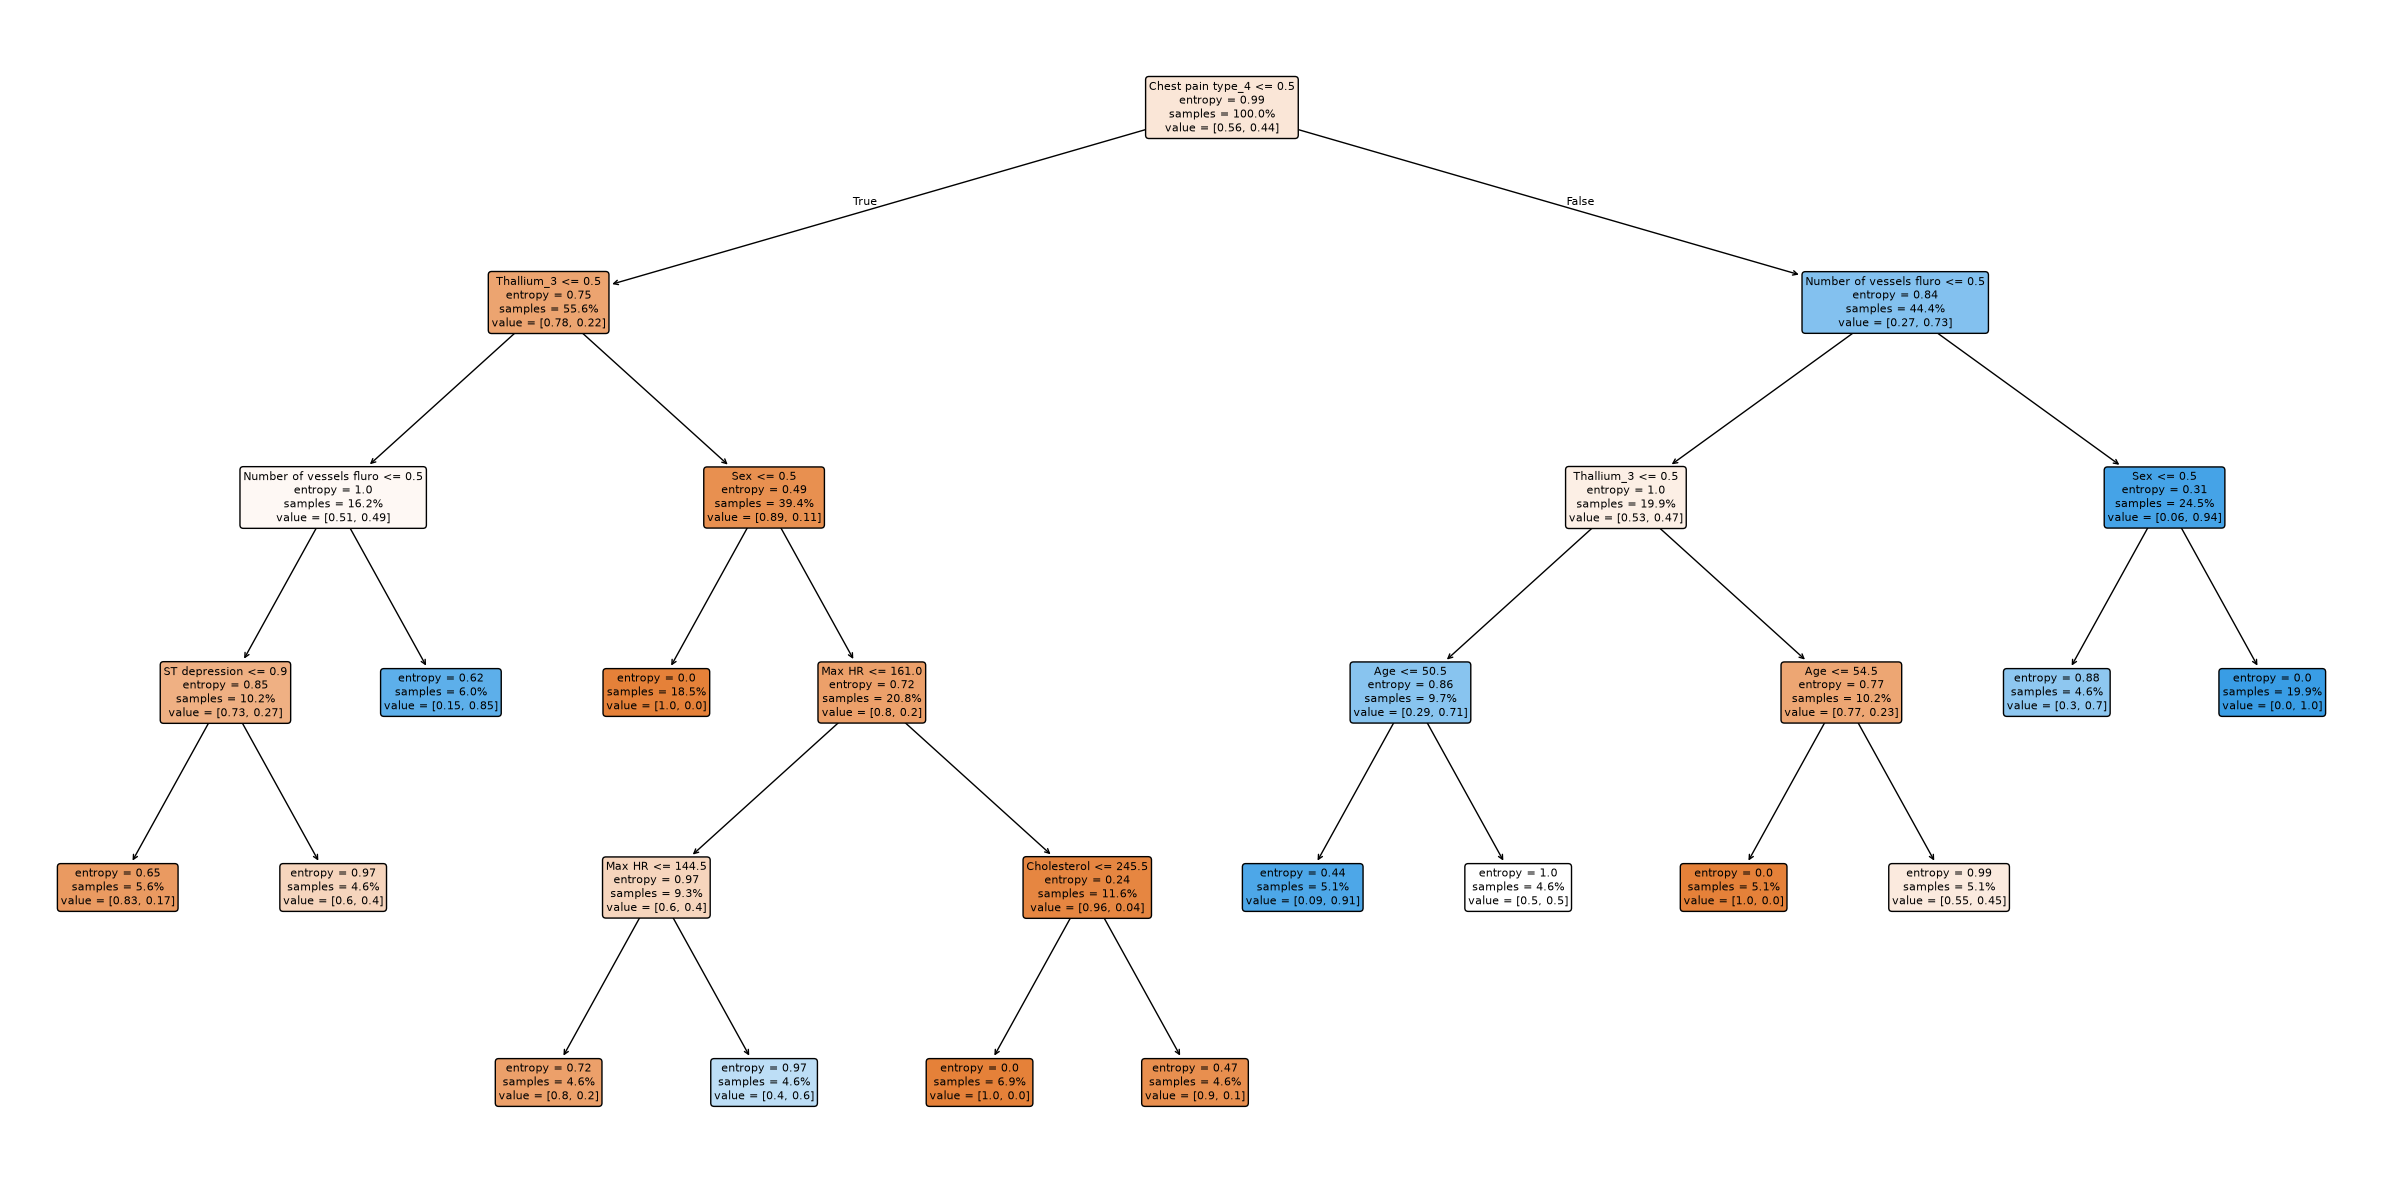

In [290]:
plt_tree_visualization(width=24, 
                       height=12,
                       fontsize=8,
                       model=model_tree_final,
                       feature_names=X_Features.columns,
                       max_depth=grid_search.best_params_['max_depth']
                       )

In [291]:
## Vendo o resultado do treinamento com max_depth

predict_treino_final = model_tree_final.predict(X_Features_treino)

accuracy_treino_final = accuracy_score(y_target_treino, predict_treino_final)
print(f"Acurácia do modelo final no conjunto de treino: {accuracy_treino_final:.2f}")

accuracy_teste_final = accuracy_score(y_target_teste, predict_final)
print(f"Acurácia do modelo final no conjunto de teste: {accuracy_teste_final:.2f}")

Acurácia do modelo final no conjunto de treino: 0.87
Acurácia do modelo final no conjunto de teste: 0.74


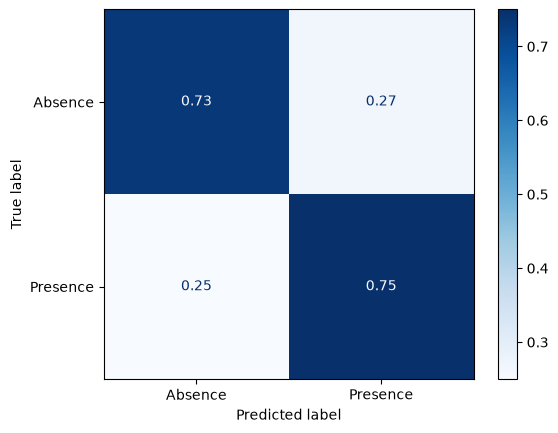

In [292]:
## Matriz de Confusão do modelo final

ConfusionMatrixDisplay.from_estimator(model_tree_final,
                                      X_Features_teste,
                                      y_target_teste,
                                      normalize='true',
                                      cmap=plt.cm.Blues)

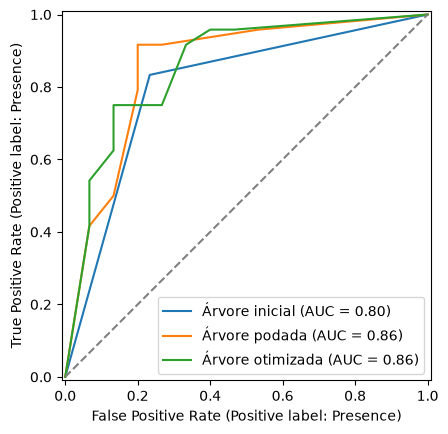

In [293]:
ax = RocCurveDisplay.from_estimator(
    model_tree,
    X_Features_teste,
    y_target_teste,
    name='Árvore inicial',
    pos_label='Presence'
).ax_

RocCurveDisplay.from_estimator(
    model_tree_depth,
    X_Features_teste,
    y_target_teste,
    name='Árvore podada',
    pos_label='Presence',
    ax=ax
)

RocCurveDisplay.from_estimator(
    model_tree_final,
    X_Features_teste,
    y_target_teste,
    name='Árvore otimizada',
    pos_label='Presence',
    ax=ax
)

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.legend()
plt.show()